# COVID-19 Global Impact Analysis
**Focused question:** *Does testing intensity explain how different countries look in the COVID-19 numbers, and what does that mean for comparing "cases", "deaths" and "fatality rate" across the world?*

**Data:** Worldometer country-level summary (226 countries/territories, one row per country).
The file has no dates and no vaccination columns, so it is a **snapshot**. Judging by the US total (~1.03 million deaths) it appears to date from roughly mid-May 2022 (inferred, not stated in the file).
Because of that, time-series metrics (7-day rolling average, doubling time) and vaccination-rollout analysis are **not possible** with this file. Everything below uses cumulative, per-population and testing metrics instead.

**Pipeline:** `clean_data.py` (cleaning + feature engineering) -> this notebook (analysis + charts) -> Power BI dashboard (see `POWERBI_GUIDE.md`).

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy import stats
import warnings; warnings.filterwarnings("ignore")

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "font.family": "DejaVu Sans", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
def save(fig, name):
    fig.savefig(f"../charts/{name}.png", dpi=200, bbox_inches="tight")

df = pd.read_csv("../data/covid_cleaned.csv")
s = df[df.analysis_sample].copy()                 # countries with >=1M people and >=1,000 cases
t = s.dropna(subset=["tests_per_1m"]).copy()      # ... and with testing data
print(f"All rows: {len(df)} | analysis sample: {len(s)} | with testing data: {len(t)}")

All rows: 226 | analysis sample: 157 | with testing data: 154


## 1. Data overview and quality

In [2]:
raw = pd.read_csv("../data/raw_worldometer_coronavirus_summary_data.csv")
print("Missing values in the RAW file:")
print(raw.isna().sum()[raw.isna().sum() > 0].to_string())
print()
print("World totals in file:  cases = {:,.0f} | deaths = {:,.0f} | population = {:,.0f}".format(
    df.total_confirmed.sum(), df.total_deaths.sum(), df.population.sum()))
print("World crude case fatality rate: {:.2f}%".format(df.total_deaths.sum()/df.total_confirmed.sum()*100))
df[["cases_per_1m","deaths_per_1m","tests_per_1m","cfr_pct","cumulative_positivity_pct"]].describe().round(1)

Missing values in the RAW file:
total_deaths                       8
total_recovered                   22
active_cases                      22
serious_or_critical               81
total_deaths_per_1m_population     8
total_tests                       14
total_tests_per_1m_population     14

World totals in file:  cases = 521,077,152 | deaths = 6,288,083 | population = 7,899,878,348
World crude case fatality rate: 1.21%


,cases_per_1m,deaths_per_1m,tests_per_1m,cfr_pct,cumulative_positivity_pct
count,226.0,226.0,212.0,226.0,209.0
mean,148156.8,1116.6,1944649.8,1.4,13.0
std,155202.9,1210.2,3318400.1,1.7,9.4
min,16.0,0.0,5093.4,0.0,0.1
25%,11748.1,124.9,166725.6,0.5,6.6
50%,98271.2,709.3,775335.6,1.0,10.6
75%,255633.0,1843.1,2267408.6,1.9,16.9
max,704302.1,6297.4,21842472.2,18.2,61.7


## 2. Insight 1 - The burden is very unevenly spread (and reporting is uneven too)
Africa holds ~18% of the world's people in this file but only ~2% of reported cases and ~4% of reported deaths. Europe holds ~9% of the people but ~37% of cases and ~29% of deaths. South America has the highest deaths per million and the highest fatality rate of any continent.

,countries,pop_share_%,case_share_%,death_share_%,cases_per_1m,deaths_per_1m,cfr_%
continent,,,,,,,
South America,14,5.5,11.0,20.6,130633.6,2964.3,2.3
North America,39,7.6,19.1,23.3,166679.7,2454.8,1.5
Europe,48,9.5,37.3,29.1,259636.2,2445.9,0.9
Asia,49,59.1,28.8,22.7,32103.0,305.6,1.0
Oceania,18,0.6,1.5,0.2,182571.1,262.3,0.1
Africa,58,17.7,2.3,4.0,8599.5,181.6,2.1


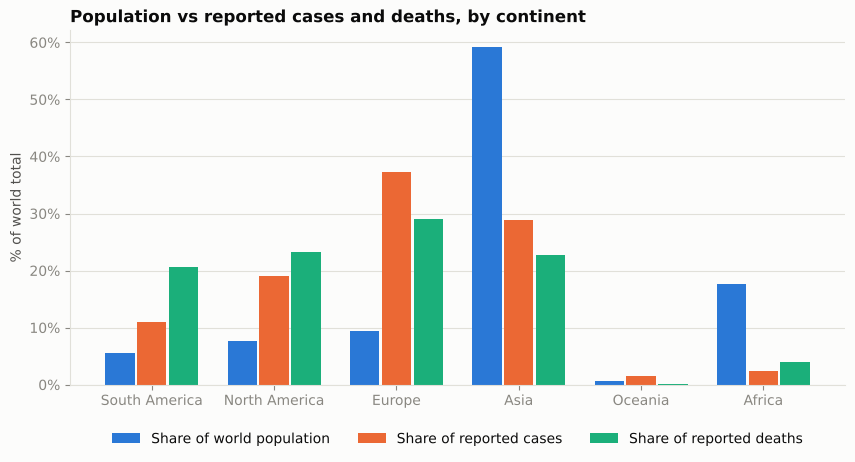

In [3]:
g = df.groupby("continent").agg(population=("population","sum"), cases=("total_confirmed","sum"),
        deaths=("total_deaths","sum"), tests=("total_tests","sum"), countries=("country","count"))
g["pop_share_%"]   = g.population/g.population.sum()*100
g["case_share_%"]  = g.cases/g.cases.sum()*100
g["death_share_%"] = g.deaths/g.deaths.sum()*100
g["cases_per_1m"]  = g.cases/g.population*1e6
g["deaths_per_1m"] = g.deaths/g.population*1e6
g["cfr_%"]         = g.deaths/g.cases*100
g = g.sort_values("deaths_per_1m", ascending=False)
display(g.round(1)[["countries","pop_share_%","case_share_%","death_share_%","cases_per_1m","deaths_per_1m","cfr_%"]])

fig, ax = plt.subplots(figsize=(10, 4.6))
x = np.arange(len(g)); w = 0.26
ax.bar(x-w, g["pop_share_%"],   w-0.02, color=BLUE,   label="Share of world population")
ax.bar(x,   g["case_share_%"],  w-0.02, color=ORANGE, label="Share of reported cases")
ax.bar(x+w, g["death_share_%"], w-0.02, color=AQUA,   label="Share of reported deaths")
ax.set_xticks(x); ax.set_xticklabels(g.index, rotation=0)
ax.set_ylabel("% of world total"); ax.yaxis.set_major_formatter(FuncFormatter(lambda v,_: f"{v:.0f}%"))
ax.set_title("Population vs reported cases and deaths, by continent")
ax.legend(frameon=False, loc="upper center", ncol=3, bbox_to_anchor=(0.5, -0.1))
ax.grid(axis="x", visible=False)
save(fig, "fig1_continent_shares"); plt.show()

## 3. Insight 2 - Reported cases mostly measure how much a country tests
Across 154 countries, tests per million people and cases per million people move almost in lockstep (Spearman rho = 0.92). The quarter of countries that test the least report a median of about 3,000 cases per million; the quarter that tests the most reports about 260,000. Nobody believes the true gap is 90x, so **cases per million is a measure of detection as much as of spread.**

Spearman rho (tests per 1M vs cases per 1M) = 0.92, p = 3.3e-64, n = 154


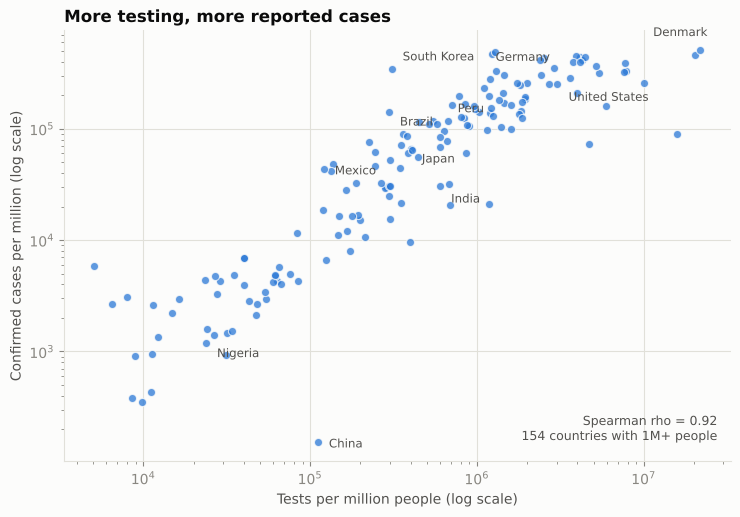

In [4]:
rho, p = stats.spearmanr(t.tests_per_1m, t.cases_per_1m)
print(f"Spearman rho (tests per 1M vs cases per 1M) = {rho:.2f}, p = {p:.1e}, n = {len(t)}")

label = ["United States","India","Peru","Denmark","Mexico","Nigeria","Japan","South Korea","China","Brazil","Germany"]
offs  = {"United States":(8,-12),"India":(8,-12),"Peru":(-8,10),"Denmark":(-34,10),"Mexico":(8,-4),"Nigeria":(8,-10),
         "Japan":(8,-10),"South Korea":(8,6),"China":(8,-4),"Brazil":(8,-10),"Germany":(-6,10)}
fig, ax = plt.subplots(figsize=(8.6, 5.6))
ax.scatter(t.tests_per_1m, t.cases_per_1m, s=34, color=BLUE, alpha=0.75, edgecolor=SURF, linewidth=0.8)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Tests per million people (log scale)"); ax.set_ylabel("Confirmed cases per million (log scale)")
for c in label:
    r = t[t.country == c]
    if len(r):
        r = r.iloc[0]
        ax.annotate(c, (r.tests_per_1m, r.cases_per_1m), xytext=offs[c], textcoords="offset points",
                    fontsize=8.5, color=INK2)
ax.set_title("More testing, more reported cases")
ax.text(0.98, 0.04, f"Spearman rho = {rho:.2f}\n{len(t)} countries with 1M+ people", transform=ax.transAxes,
        va="bottom", ha="right", fontsize=9, color=INK2)
save(fig, "fig2_tests_vs_cases"); plt.show()

## 4. Insight 3 - Fatality rates look worst where testing is thinnest
Countries in the lowest-testing quarter have a median case fatality rate (CFR) of about 1.8%, versus about 0.7% in the highest-testing quarter (rho = -0.54 between tests per million and CFR). When few cases are detected, the denominator of CFR is too small, so the rate is inflated. This is correlation, not proof of cause: health-system capacity and age structure matter too.

Spearman rho (tests per 1M vs CFR) = -0.54, p = 3.4e-13


,countries,median_tests_per_1m,median_cases_per_1m,median_cfr_pct,median_deaths_per_1m
tier,,,,,
Q1 (lowest),39,31399.58,2971.22,1.83,62.45
Q2,38,245722.15,30321.18,2.04,423.16
Q3,38,856700.11,116936.87,1.21,1636.06
Q4 (highest),39,3038938.88,259939.52,0.70,1636.38


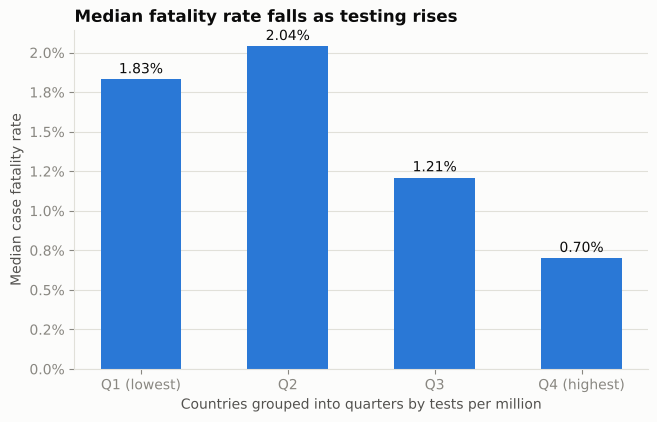

In [5]:
rho2, p2 = stats.spearmanr(t.tests_per_1m, t.cfr_pct)
print(f"Spearman rho (tests per 1M vs CFR) = {rho2:.2f}, p = {p2:.1e}")
t["tier"] = pd.qcut(t.tests_per_1m, 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
tier = t.groupby("tier").agg(countries=("country","count"), median_tests_per_1m=("tests_per_1m","median"),
        median_cases_per_1m=("cases_per_1m","median"), median_cfr_pct=("cfr_pct","median"),
        median_deaths_per_1m=("deaths_per_1m","median")).round(2)
display(tier)

fig, ax = plt.subplots(figsize=(7.4, 4.4))
bars = ax.bar(tier.index.astype(str), tier.median_cfr_pct, color=BLUE, width=0.55)
for b, v in zip(bars, tier.median_cfr_pct):
    ax.text(b.get_x()+b.get_width()/2, v+0.04, f"{v:.2f}%", ha="center", fontsize=10, color=INK)
ax.set_ylabel("Median case fatality rate"); ax.yaxis.set_major_formatter(FuncFormatter(lambda v,_: f"{v:.1f}%"))
ax.set_xlabel("Countries grouped into quarters by tests per million")
ax.set_title("Median fatality rate falls as testing rises"); ax.grid(axis="x", visible=False)
save(fig, "fig3_testing_tier_cfr"); plt.show()

## 5. Insight 4 - Deaths per million is the fairer yardstick, and it points somewhere else
Deaths are less sensitive to testing than cases, so deaths per million is the better cross-country measure. By that measure the heaviest reported burden sits in **Peru (about 6,300 per million), Bulgaria, Bosnia and Herzegovina, Hungary and North Macedonia**: mostly Central and Eastern Europe plus Peru. The lightest reported burden is concentrated in low-testing African countries and China, where under-reporting is likely, so "lowest" should be read as "lowest reported".

,country,continent,deaths_per_1m,cfr_pct,cases_per_1m,tests_per_1m
158,Peru,South America,6297.4,6.0,105593.1,893566.7
29,Bulgaria,Europe,5407.2,3.2,169536.4,1448572.8
24,Bosnia and Herzegovina,Europe,4865.5,4.2,116414.3,544957.0
90,Hungary,Europe,4820.0,2.4,198649.3,1185121.5
149,North Macedonia,Europe,4459.0,3.0,149136.8,976666.4
75,Georgia,Asia,4229.3,1.0,416417.4,4256722.2
48,Croatia,Europe,3925.5,1.4,278810.7,1192211.9
52,Czechia,Europe,3745.1,1.0,364401.1,5148341.6
185,Slovakia,Europe,3667.4,1.1,327032.9,1304244.1
165,Romania,Europe,3453.5,2.3,152803.3,1208233.2


,country,continent,deaths_per_1m,cfr_pct,cases_per_1m,tests_per_1m
31,Burundi,Africa,3.0,0.1,3285.7,27549.2
42,China,Asia,3.6,2.3,154.1,111163.3
39,Chad,Africa,11.2,2.6,428.5,11058.1
146,Niger,Africa,12.0,3.4,348.8,9793.6
191,South Sudan,Africa,12.1,0.8,1532.2,34068.2
200,Tajikistan,Asia,12.5,0.7,1749.9,NaN
20,Benin,Africa,12.8,0.6,2119.8,47529.8
201,Tanzania,Africa,13.4,2.4,562.1,NaN
53,DR Congo,Africa,14.1,1.5,919.6,8947.5
147,Nigeria,Africa,14.6,1.2,1186.4,23717.5


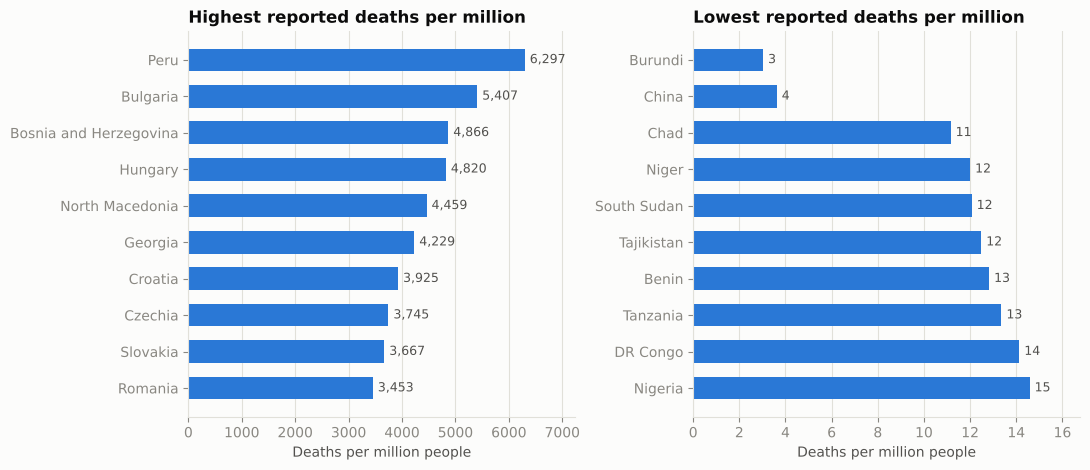

In [6]:
cols = ["country","continent","deaths_per_1m","cfr_pct","cases_per_1m","tests_per_1m"]
top = s.nlargest(10, "deaths_per_1m")[cols]; bot = s.nsmallest(10, "deaths_per_1m")[cols]
display(top.round(1)); display(bot.round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, d, title in [(axes[0], top.iloc[::-1], "Highest reported deaths per million"),
                     (axes[1], bot.iloc[::-1], "Lowest reported deaths per million")]:
    ax.barh(d.country, d.deaths_per_1m, color=BLUE, height=0.62)
    for y, v in enumerate(d.deaths_per_1m):
        ax.text(v + d.deaths_per_1m.max()*0.015, y, f"{v:,.0f}", va="center", fontsize=9, color=INK2)
    ax.set_title(title); ax.grid(axis="y", visible=False)
    ax.set_xlim(0, d.deaths_per_1m.max()*1.15); ax.set_xlabel("Deaths per million people")
fig.tight_layout(); save(fig, "fig4_deaths_per_million"); plt.show()

## 6. Insight 5 - Where positivity is high and testing is thin, the true toll is probably larger than reported
Cumulative positivity (confirmed cases / tests) is a rough warning light, but only when testing is also low: a high share of positive tests among *few* tests means testing mostly reached people who were already sick. Seven countries pair positivity above 30% with fewer than 300,000 tests per million (the sample median is about 405,000): **Brazil (48%), Eritrea, Mexico, Syria, Ecuador, Bolivia and Honduras**. Six of the seven have a fatality rate above the sample median of 1.2%, and Mexico and Syria (5.6% each) and Ecuador (4.1%) are among the highest in the world. That pattern is consistent with many missed infections, so these countries' case counts are the least comparable to those of heavy testers. (Slovenia and the Netherlands also exceed 30% positivity but test about 1.2 million per million people, so they do not fit the pattern.)

Sample median tests per 1M: 405,184 | sample median CFR: 1.22%


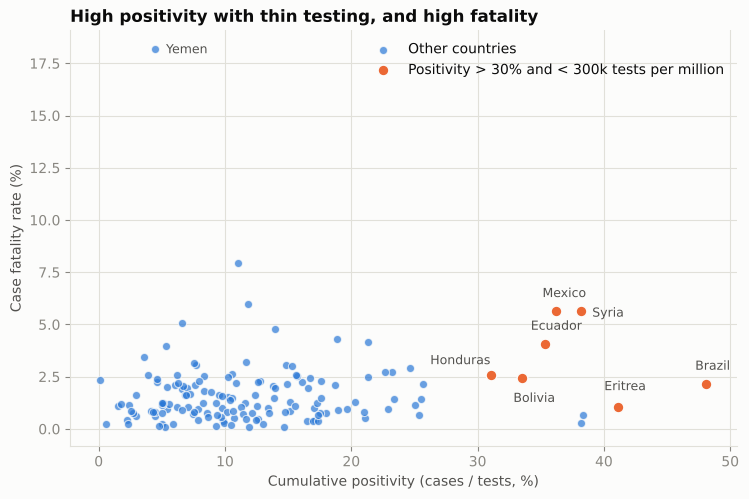

,country,cumulative_positivity_pct,cfr_pct,tests_per_1m,deaths_per_1m
23,Bolivia,33.5,2.4,226025.3,1833.2
26,Brazil,48.1,2.2,296118.9,3087.3
58,Ecuador,35.3,4.1,136157.8,1962.7
62,Eritrea,41.1,1.1,6513.0,28.3
88,Honduras,31.1,2.6,133855.8,1068.4
129,Mexico,36.2,5.6,120614.8,2468.2
198,Syria,38.2,5.6,7996.3,172.2


In [7]:
p_ = t.dropna(subset=["cumulative_positivity_pct"]).copy()
flag = (p_.cumulative_positivity_pct > 30) & (p_.tests_per_1m < 300_000)
hi, rest = p_[flag], p_[~flag]
print(f"Sample median tests per 1M: {t.tests_per_1m.median():,.0f} | sample median CFR: {t.cfr_pct.median():.2f}%")
fig, ax = plt.subplots(figsize=(8.6, 5.4))
ax.scatter(rest.cumulative_positivity_pct, rest.cfr_pct, s=34, color=BLUE, alpha=0.7, edgecolor=SURF, linewidth=0.8, label="Other countries")
ax.scatter(hi.cumulative_positivity_pct, hi.cfr_pct, s=60, color=ORANGE, edgecolor=SURF, linewidth=1,
           label="Positivity > 30% and < 300k tests per million")
offs5 = {"Brazil":(-8,10),"Eritrea":(-10,12),"Mexico":(-10,10),"Syria":(8,-4),"Ecuador":(-10,10),"Bolivia":(-6,-17),"Honduras":(-44,8)}
for _, r in hi.iterrows():
    ax.annotate(r.country, (r.cumulative_positivity_pct, r.cfr_pct), xytext=offs5.get(r.country,(7,4)),
                textcoords="offset points", fontsize=9, color=INK2)
y = p_[p_.country == "Yemen"].iloc[0]
ax.annotate("Yemen", (y.cumulative_positivity_pct, y.cfr_pct), xytext=(8,-3), textcoords="offset points", fontsize=9, color=INK2)
ax.set_xlabel("Cumulative positivity (cases / tests, %)"); ax.set_ylabel("Case fatality rate (%)")
ax.set_title("High positivity with thin testing, and high fatality")
ax.legend(frameon=False, loc="upper right")
save(fig, "fig5_positivity_vs_cfr"); plt.show()
display(hi[["country","cumulative_positivity_pct","cfr_pct","tests_per_1m","deaths_per_1m"]].round(1))

## 7. Data quality and limits (read before quoting any number)
- **Recovered / active cases are unreliable for comparison.** 22 countries have no recovery figure, and 16 more report suspiciously low recoveries (for example Martinique 0.07% recovered, Guadeloupe 1.6%, Taiwan 7.9%), which makes their active-case counts almost equal to all cases ever reported. These are flagged (`recovery_data_stale`) and kept out of the story.
- **Serious/critical** is blank for 81 rows and was not used.
- **Snapshot only.** No dates, no vaccinations: no waves, no rollout speed, no rolling averages or doubling time.
- **Reporting differs by country** (what counts as a test, a case or a COVID death), so all comparisons describe *reported* numbers.
- 69 countries with fewer than 1 million people were kept in the cleaned file but left out of rankings and correlations because per-million values swing wildly for tiny populations.

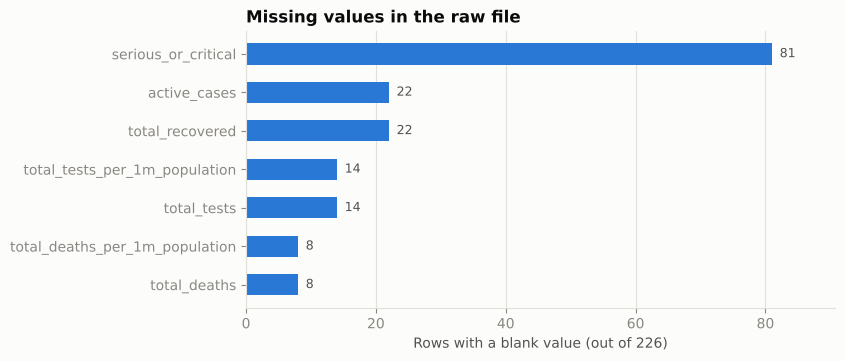

In [8]:
miss = raw.isna().sum()[raw.isna().sum() > 0].sort_values()
fig, ax = plt.subplots(figsize=(7.6, 3.6))
ax.barh(miss.index, miss.values, color=BLUE, height=0.55)
for y, v in enumerate(miss.values):
    ax.text(v+1.2, y, str(v), va="center", fontsize=9, color=INK2)
ax.set_xlabel("Rows with a blank value (out of 226)"); ax.set_title("Missing values in the raw file")
ax.grid(axis="y", visible=False); ax.set_xlim(0, miss.max()*1.12)
save(fig, "fig6_missing_values"); plt.show()

## 8. Conclusions
1. Raw case counts are a testing story as much as an infection story, so compare countries on **deaths per million**, and treat **CFR and cases per million with care**.
2. Reported burden is concentrated in Europe and the Americas; Africa's low numbers sit alongside very low testing, so they should not be read as "COVID barely happened".
3. The heaviest reported death tolls per person are in Peru and Central/Eastern Europe.
4. To answer the vaccination question in the original brief you would need the Our World in Data time series; this notebook and the Power BI model are structured so that file can be dropped in and joined on `country`.